Final Weight: 1.9999999999676041
Final Loss: 1.8975159593291566e-20


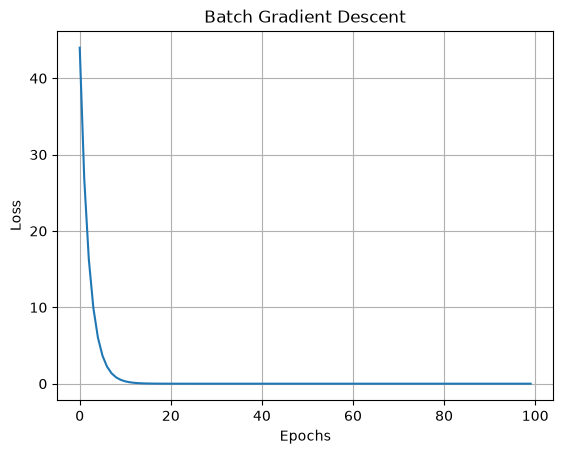

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Training data
X = np.array([1, 2, 3, 4, 5], dtype=float)
Y = np.array([2, 4, 6, 8, 10], dtype=float)

# Initial weight
w = 0.0

learning_rate = 0.01
epochs = 100

loss_history = []

# Batch Gradient Descent
for epoch in range(epochs):

    # Predictions using all training samples
    predictions = w * X

    # Calculate loss
    loss = np.mean((predictions - Y) ** 2)

    # Calculate gradient using entire dataset
    gradient = np.mean(2 * X * (predictions - Y))

    # Update weight
    w = w - learning_rate * gradient

    loss_history.append(loss)

print("Final Weight:", w)
print("Final Loss:", loss_history[-1])

# Plot loss convergence
plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Batch Gradient Descent")
plt.grid()
plt.show()

Final Weight: 2.0
Final Loss: 0.0


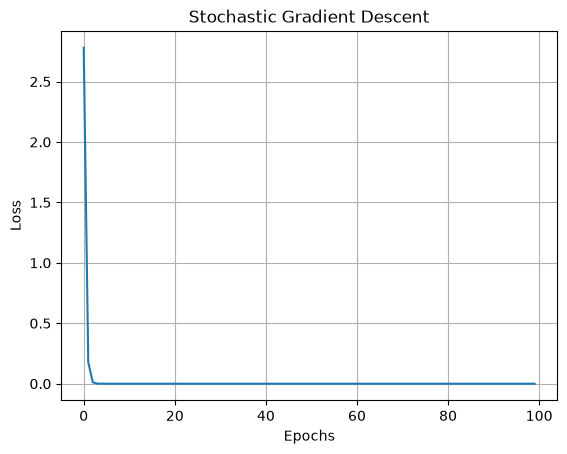

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Training data
X = np.array([1, 2, 3, 4, 5], dtype=float)
Y = np.array([2, 4, 6, 8, 10], dtype=float)

# Initial weight
w = 0.0

learning_rate = 0.01
epochs = 100

loss_history = []

# Stochastic Gradient Descent
for epoch in range(epochs):

    # Shuffle training samples
    indices = np.random.permutation(len(X))

    for i in indices:

        # One training sample
        x = X[i]
        y = Y[i]

        # Prediction
        prediction = w * x

        # Gradient for one sample
        gradient = 2 * x * (prediction - y)

        # Update weight
        w = w - learning_rate * gradient

    # Calculate total dataset loss after each epoch
    predictions = w * X
    loss = np.mean((predictions - Y) ** 2)

    loss_history.append(loss)

print("Final Weight:", w)
print("Final Loss:", loss_history[-1])

# Plot convergence
plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Stochastic Gradient Descent")
plt.grid()
plt.show()

Final Weight: 2.0023036941665473
Final Loss: 0.0005576021954022444


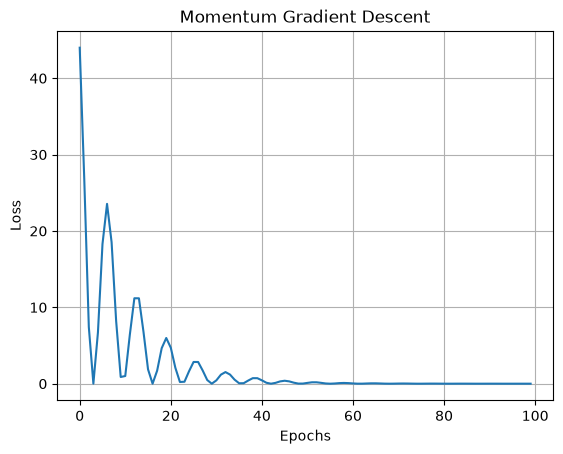

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Training data
X = np.array([1, 2, 3, 4, 5], dtype=float)
Y = np.array([2, 4, 6, 8, 10], dtype=float)

# Initial values
w = 0.0
velocity = 0.0

learning_rate = 0.01
momentum = 0.9
epochs = 100

loss_history = []

# Momentum Gradient Descent
for epoch in range(epochs):

    predictions = w * X

    loss = np.mean((predictions - Y) ** 2)

    gradient = np.mean(2 * X * (predictions - Y))

    velocity = momentum * velocity + gradient

    w = w - learning_rate * velocity

    loss_history.append(loss)

print("Final Weight:", w)
print("Final Loss:", loss_history[-1])

plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Momentum Gradient Descent")
plt.grid()
plt.show()

Final Weight: 2.000000009729473
Final Loss: 1.0412890435284778e-15


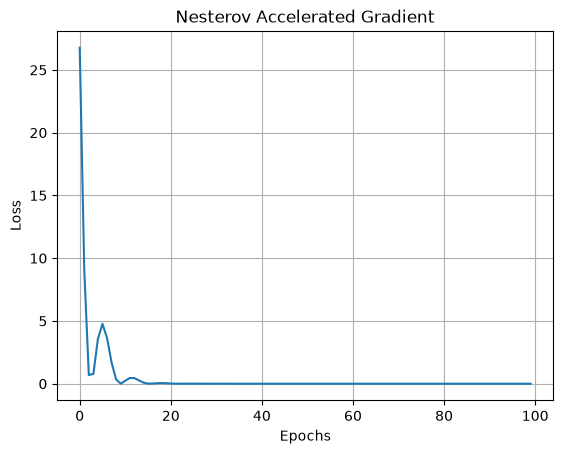

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Training data
X = np.array([1, 2, 3, 4, 5], dtype=float)
Y = np.array([2, 4, 6, 8, 10], dtype=float)

# Initial values
w = 0.0
velocity = 0.0

learning_rate = 0.01
momentum = 0.9
epochs = 100

loss_history = []

# Nesterov Accelerated Gradient
for epoch in range(epochs):

    # Lookahead position
    lookahead_w = w - learning_rate * momentum * velocity

    # Calculate gradient at lookahead position
    predictions = lookahead_w * X
    gradient = np.mean(2 * X * (predictions - Y))

    # Update velocity and weight
    velocity = momentum * velocity + gradient
    w = w - learning_rate * velocity

    # Calculate loss at updated weight
    predictions = w * X
    loss = np.mean((predictions - Y) ** 2)

    loss_history.append(loss)

print("Final Weight:", w)
print("Final Loss:", loss_history[-1])

plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Nesterov Accelerated Gradient")
plt.grid()
plt.show()

OPTIMIZATION COMPARISON
----------------------------------------
Batch GD: Weight = 2.0000, Loss = 0.00000000
SGD: Weight = 2.0000, Loss = 0.00000000
Momentum: Weight = 2.0023, Loss = 0.00005838
Nesterov: Weight = 2.0000, Loss = 0.00000000


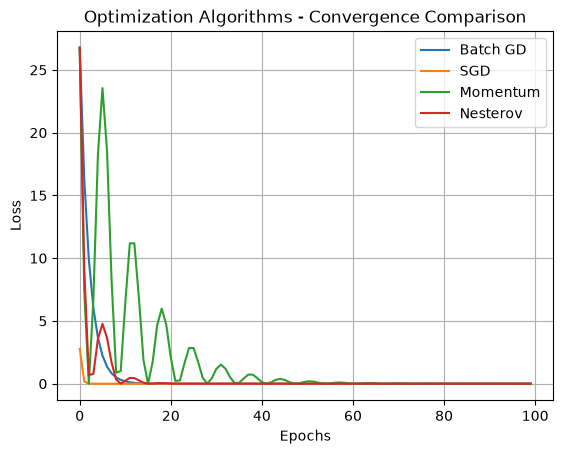

In [6]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([1, 2, 3, 4, 5], dtype=float)
Y = np.array([2, 4, 6, 8, 10], dtype=float)

learning_rate = 0.01
momentum = 0.9
epochs = 100

# Loss function
def calculate_loss(w):
    return np.mean((w * X - Y) ** 2)

# Gradient function
def calculate_gradient(w):
    return np.mean(2 * X * (w * X - Y))


# 1. Batch Gradient Descent
def batch_gd():
    w = 0.0
    history = []

    for _ in range(epochs):
        gradient = calculate_gradient(w)
        w -= learning_rate * gradient
        history.append(calculate_loss(w))

    return w, history


# 2. Stochastic Gradient Descent
def stochastic_gd():
    w = 0.0
    history = []
    rng = np.random.default_rng(42)

    for _ in range(epochs):
        for i in rng.permutation(len(X)):
            gradient = 2 * X[i] * (w * X[i] - Y[i])
            w -= learning_rate * gradient

        history.append(calculate_loss(w))

    return w, history


# 3. Momentum Gradient Descent
def momentum_gd():
    w = 0.0
    velocity = 0.0
    history = []

    for _ in range(epochs):
        gradient = calculate_gradient(w)
        velocity = momentum * velocity + gradient
        w -= learning_rate * velocity
        history.append(calculate_loss(w))

    return w, history


# 4. Nesterov Accelerated Gradient
def nesterov_gd():
    w = 0.0
    velocity = 0.0
    history = []

    for _ in range(epochs):
        lookahead = w - learning_rate * momentum * velocity
        gradient = calculate_gradient(lookahead)

        velocity = momentum * velocity + gradient
        w -= learning_rate * velocity

        history.append(calculate_loss(w))

    return w, history


# Run all algorithms
results = {
    "Batch GD": batch_gd(),
    "SGD": stochastic_gd(),
    "Momentum": momentum_gd(),
    "Nesterov": nesterov_gd()
}

# Display final results
print("OPTIMIZATION COMPARISON")
print("-" * 40)

for name, (weight, history) in results.items():
    print(f"{name}: Weight = {weight:.4f}, Loss = {history[-1]:.8f}")

# Plot comparison
for name, (weight, history) in results.items():
    plt.plot(history, label=name)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Optimization Algorithms - Convergence Comparison")
plt.legend()
plt.grid()
plt.show()

Overfitting Model
Training Error: 0.16333600200471582
Testing Error: 0.3399208256789479

Regularized Model
Training Error: 0.012822761426898302
Testing Error: 0.05958439169361191


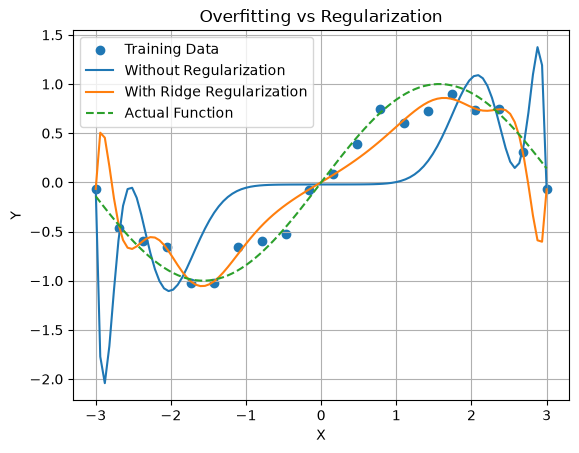

In [7]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline

# Generate training data
np.random.seed(42)

X = np.linspace(-3, 3, 20).reshape(-1, 1)
Y = np.sin(X).ravel() + np.random.normal(0, 0.15, 20)

# Generate test data
X_test = np.linspace(-3, 3, 100).reshape(-1, 1)
Y_test = np.sin(X_test).ravel()

# Model 1: High-degree polynomial without regularization
overfit_model = make_pipeline(
    PolynomialFeatures(degree=15),
    LinearRegression()
)

# Model 2: High-degree polynomial with Ridge regularization
regularized_model = make_pipeline(
    PolynomialFeatures(degree=15),
    Ridge(alpha=1.0)
)

# Train both models
overfit_model.fit(X, Y)
regularized_model.fit(X, Y)

# Predictions
overfit_predictions = overfit_model.predict(X_test)
regularized_predictions = regularized_model.predict(X_test)

# Calculate errors
print("Overfitting Model")
print("Training Error:",
      np.mean((overfit_model.predict(X) - Y) ** 2))
print("Testing Error:",
      np.mean((overfit_predictions - Y_test) ** 2))

print("\nRegularized Model")
print("Training Error:",
      np.mean((regularized_model.predict(X) - Y) ** 2))
print("Testing Error:",
      np.mean((regularized_predictions - Y_test) ** 2))

# Visualization
plt.scatter(X, Y, label="Training Data")

plt.plot(
    X_test,
    overfit_predictions,
    label="Without Regularization"
)

plt.plot(
    X_test,
    regularized_predictions,
    label="With Ridge Regularization"
)

plt.plot(
    X_test,
    Y_test,
    label="Actual Function",
    linestyle="--"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Overfitting vs Regularization")
plt.legend()
plt.grid()
plt.show()